# Homework 9


**Concepts covered:**

matplotlib, line charts, pie chart, histogram, scatterplot

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning against using generative AI:**

We recommend *in the strongest terms* against using generative AI in solving any homework assignment in this module. The goal of these assignments is for you to learn the fundamental concepts about programming: syntax, correctness, problem decomposition, and skepticism. While we know that generative AI can solve all of these problems, you will not be learning anything and will get confused as this module progresses.

While we encourage you to use AI to generate practice problems, you should try to solve these problems with the help of the sample problems, and examples on blackboard and experimentation.



**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.


## Shared Imports

Run the cell below to import modules that will be used through out
this homework notebook. Do not import any other modules.
In particular, other charting modules such as Seaborn are not allowed.

In [59]:
import sys
print(sys.executable)

/workspaces/homework/.venv/bin/python


In [60]:
!python -m pip install numpy matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [61]:
# shared imports
import math
import numpy as np
import matplotlib.pyplot as plt


**NOTE: Use the appropriate and optimal ranges for the axis values so that the visualizations are not too small.**


**This homework is partially autograded. The plots will be manually graded so please allow some time for you to get a full score.**

**Problem 1 (review)**

**Concept:** *NumPy arrays, math functions*

**Task:**

Write three functions that generate numerical arrays using NumPy.

Each function takes three parameters:

* **start** – the starting value of the array

* **stop** – the ending value of the array (not inclusive)

* **steps** – the increment between values in the array (the step size used by `np.arange`)

Use `np.arange(start, stop, steps)` to generate the base array of values. Then apply the requested NumPy math function to the entire array.

**Functions to Implement:**

1. `generate_sine_wave(start, stop, steps)`

* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Compute the sine of each value using `np.sin`.
* Return the array of sine values.
2. `generate_logs(start, stop, steps)`
* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Compute the natural logarithm of each value using `np.log`.
* Return the array of log values.
3. `generate_rounded(start, stop, steps)`
* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Round each value using `np.round`.
* Return the rounded array.



In [62]:
# Your Solution
def generate_sine_wave(start, stop, steps):
    """
    Generate an array and calculate the sine of each value.
    """
    # Generate the base array using the specified step size.
    values = np.arange(start, stop, steps)

    # Calculate the sine of every value.
    sine_values = np.sin(values)

    return sine_values


def generate_logs(start, stop, steps):
    """
    Generate an array and calculate the natural logarithm of each value.
    """
    # Generate the base array using the specified step size.
    values = np.arange(start, stop, steps)

    # Calculate the natural logarithm of every value.
    log_values = np.log(values)

    return log_values


def generate_rounded(start, stop, steps):
    """
    Generate an array and round each value.
    """
    # Generate the base array using the specified step size.
    values = np.arange(start, stop, steps)

    # Round every value in the array.
    rounded_values = np.round(values)

    return rounded_values

In [63]:
print(generate_sine_wave(0, 10, 1))
print(generate_logs(1, 10, 1))
print(generate_rounded(0, 10, 0.5))

[ 0.          0.84147098  0.90929743  0.14112001 -0.7568025  -0.95892427
 -0.2794155   0.6569866   0.98935825  0.41211849]
[0.         0.69314718 1.09861229 1.38629436 1.60943791 1.79175947
 1.94591015 2.07944154 2.19722458]
[ 0.  0.  1.  2.  2.  2.  3.  4.  4.  4.  5.  6.  6.  6.  7.  8.  8.  8.
  9. 10.]


**Problem 2 (review)**

**Concept:** *reading CSV file, create an np.array of numbers*

**Task:**

Write a function `read_csv_to_dict(filename)` that reads a CSV file and stores the data in a dictionary.

Your function should:
1. Open the CSV file.
2. Read the first row to obtain column headers.
3. Store each column of data as a NumPy array.
4. Use the column names as keys in the dictionary.
5. Return the dictionary.

Each key should correspond to one column in the CSV file.

Example structure:

```
{
   "open": np.array([...]),
   "close": np.array([...]),
   "volume": np.array([...])
}
```


In [64]:
#Your Solution
def read_csv_to_dict(filename):
    """
    Read a CSV file and store each column as a NumPy array in a dictionary.
    """
    data_dict = {}

    # Open the CSV file.
    with open(filename, "r") as file:

        # Read the column headers.
        headers = file.readline().strip().split(",")

        # Create an empty list for each column.
        for header in headers:
            data_dict[header] = []

        # Read each remaining row.
        for line in file:
            values = line.strip().split(",")

            # Add each value to its corresponding column.
            for i in range(len(headers)):
                data_dict[headers[i]].append(values[i])

    # Convert each column into a NumPy array.
    for header in headers:
        try:
            data_dict[header] = np.array(data_dict[header], dtype=float)
        except ValueError:
            data_dict[header] = np.array(data_dict[header], dtype=str)

    return data_dict


**Problem 3**

**Concepts:** *matplotlib, plt line*

**Task:**

Use NumPy and Matplotlib to generate and plot sine and cosine waves.

Complete the following steps:

1. Create a range of values from **0 to 20** using `np.arange`.
2. Compute:
* the sine wave
* the cosine wave

Create four plots:
1. Plot the **sine wave** by itself.
2. Plot the **cosine wave** by itself.
3. Plot **both waves together on the same chart** with a legend.
4. Compute the **ratio of sine to cosine** and plot it.

Each chart should include a **title**, and the combined chart should include a **legend**.


In [88]:
x = np.arange(0, 20, 0.1)
sine_wave = np.sin(x)
cosine_wave = np.cos(x)

**Plot 1:**

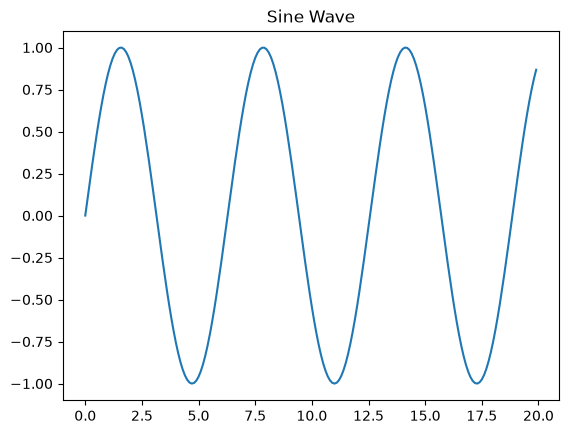

In [66]:
#Your Solution
plt.plot(x, sine_wave)
plt.title("Sine Wave")
plt.show()

**Plot 2:**

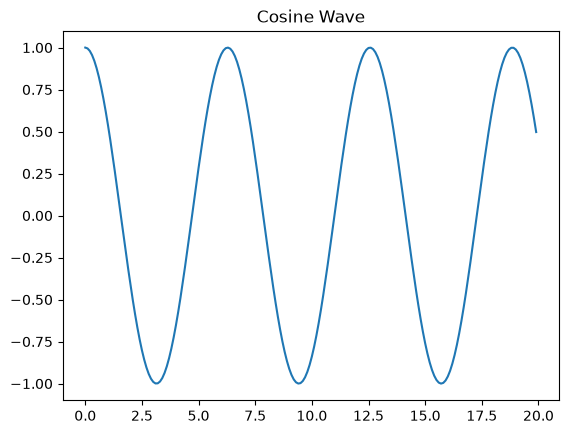

In [67]:
#Your Solution
plt.plot(x, cosine_wave)
plt.title("Cosine Wave")
plt.show()

**Plot 3:**

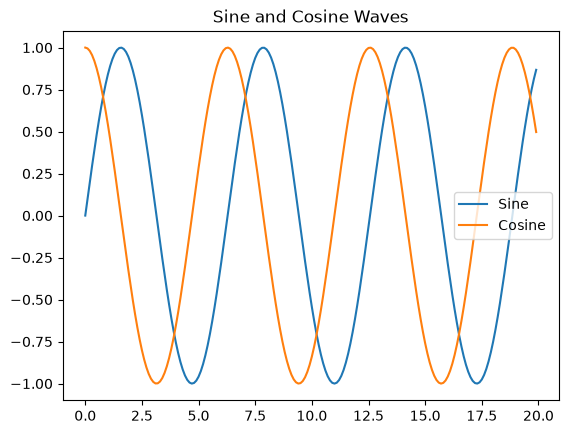

In [68]:
#Your Solution
plt.plot(x, sine_wave, label="Sine")
plt.plot(x, cosine_wave, label="Cosine")
plt.title("Sine and Cosine Waves")
plt.legend()
plt.show()

**Plot 4:**

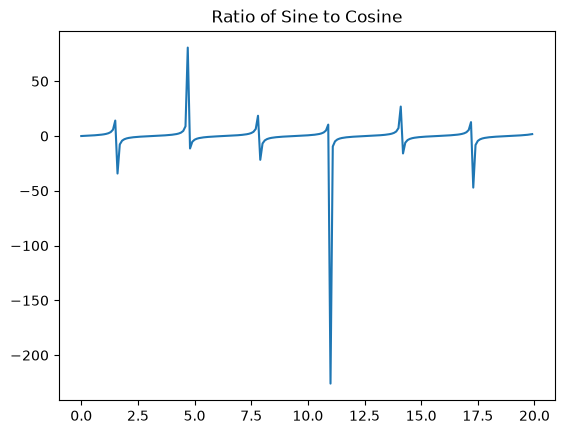

In [69]:
#Your Solution
ratio = sine_wave / cosine_wave

plt.plot(x, ratio)
plt.title("Ratio of Sine to Cosine")
plt.show()

**Problem 4**

**Concepts:** *matplotlib, bar chart*

**Task:**

Use the provided lists representing fruit consumption over several days.

Create the following visualizations:

1. A **stacked bar chart** showing strawberry and banana consumption.
2. Two **separate bar charts using subplots**:
* One chart for strawberries (red)
* One chart for bananas (yellow)

Each chart should include:
* a title
* a legend

In [70]:
# STARTER CODE; DO NOT CHANGE
days = range(10)
strawberries = [1, 2, 2, 4, 2, 5, 6, 5, 6, 8]
bananas = [1, 1, 1, 2, 2, 2, 3, 3, 3, 4]


**Plot 1: Stacked Bar Chart**

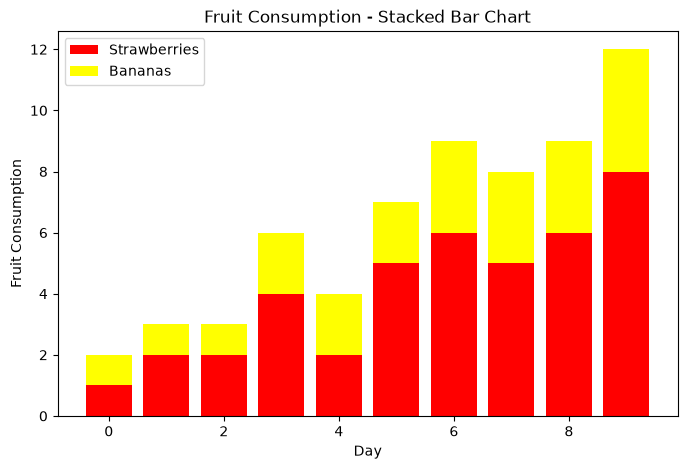

In [71]:
#Your Solution
plt.figure(figsize=(8, 5))

plt.bar(days, strawberries, color="red", label="Strawberries")
plt.bar(days, bananas, bottom=strawberries, color="yellow", label="Bananas")

plt.title("Fruit Consumption - Stacked Bar Chart")
plt.xlabel("Day")
plt.ylabel("Fruit Consumption")
plt.legend()

plt.show()

**Plot 2: Separate Bar Chart**

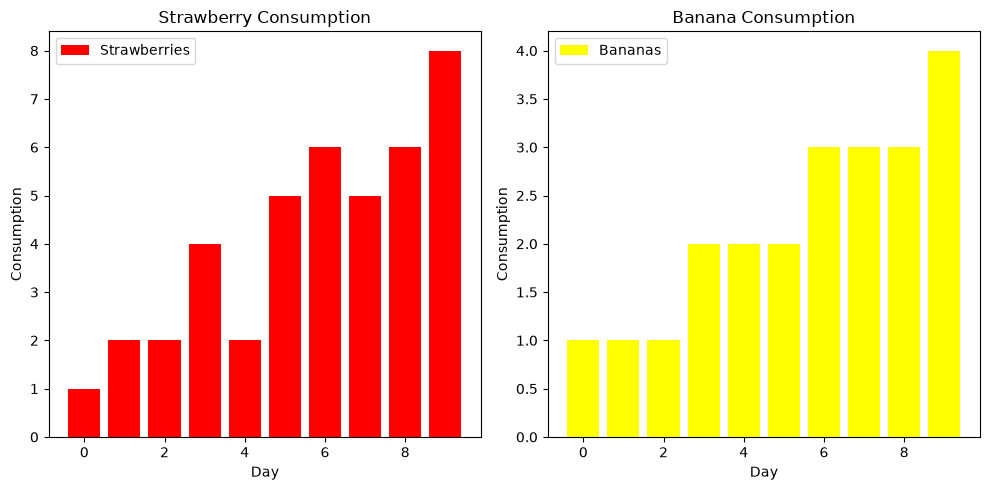

In [72]:
#Your Solution
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Strawberry bar chart
axes[0].bar(days, strawberries, color="red", label="Strawberries")
axes[0].set_title("Strawberry Consumption")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Consumption")
axes[0].legend()

# Banana bar chart
axes[1].bar(days, bananas, color="yellow", label="Bananas")
axes[1].set_title("Banana Consumption")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Consumption")
axes[1].legend()

plt.tight_layout()
plt.show()

**Problem 5**

**Concepts:** *matplotlib, bar chart*

**Task:**

Using the same fruit consumption data from Problem 4, create a **grouped bar chart**.

Your chart should:
1. Display strawberries (red) and bananas (yellow) side-by-side for each day.
2. Use a bar width to offset the second set of bars.
3. Label the x-axis with the day numbers.
4. Include:
    * axis labels
    * a title
    * a legend

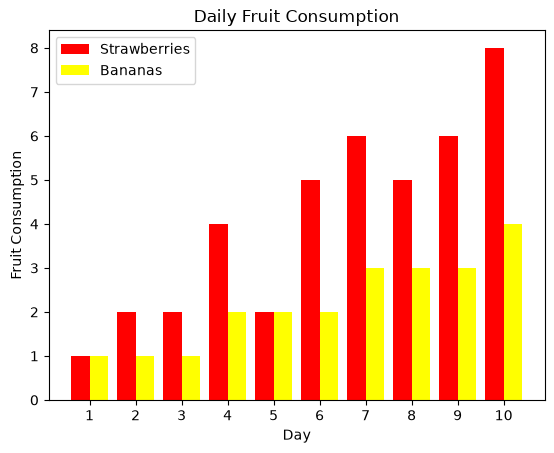

In [73]:
# STARTER CODE; DO NOT CHANGE
days = range(10)
strawberries = [1, 2, 2, 4, 2, 5, 6, 5, 6, 8]
bananas = [1, 1, 1, 2, 2, 2, 3, 3, 3, 4]

#Your Solution
# Set the positions for each day
days = np.arange(len(strawberries))

# Set the bar width
width = 0.4

# Create the strawberries bars
plt.bar(days - width/2, strawberries, width,
        color="red", label="Strawberries")

# Create the bananas bars
plt.bar(days + width/2, bananas, width,
        color="yellow", label="Bananas")

# Add axis labels and title
plt.xlabel("Day")
plt.ylabel("Fruit Consumption")
plt.title("Daily Fruit Consumption")

# Add day numbers to the x-axis
plt.xticks(days, days + 1)

# Add legend
plt.legend()

# Display the chart
plt.show()




**Problem 6**

**Concepts:** *matplotlib, scatter plot*


**Task:**

Create a scatter plot that displays the points of a **unit circle**.

Steps:

1. Generate `x` values between **0 and 1**.
2. Compute the corresponding `y` values using the circle equation:

$$y = sqrt(1 − x²)$$

3. Reflect the points across all four quadrants so that the full circle is drawn.
4. Plot the points using `plt.scatter`.

Set the figure size to **(5,5)** so the circle appears correctly proportioned.

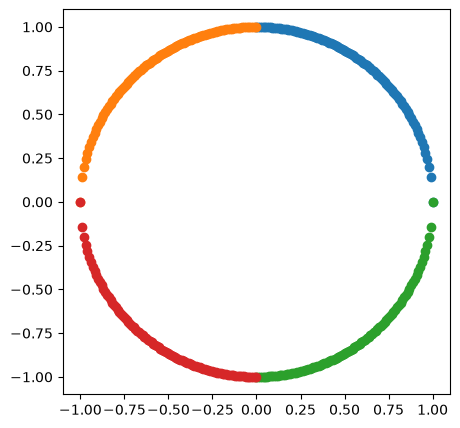

In [74]:
#Your Solution
# Generate x values between 0 and 1
x = np.linspace(0, 1, 100)

# Calculate the corresponding y values
y = np.sqrt(1 - x**2)

# Set the figure size
plt.figure(figsize=(5, 5))

# Plot points in all four quadrants
plt.scatter(x, y)
plt.scatter(-x, y)
plt.scatter(x, -y)
plt.scatter(-x, -y)

# Display the circle
plt.show()

**Problem 7**

**Concepts:** *matplotlib, scatter plot*

**Task:**

Create a scatter plot using the provided `x_data` and `y_data`.

Plot the data **four different ways on the same chart**:
1. Original values `(x, y)`
2. Horizontal reflection `(-x, y)`
3. Vertical reflection `(x, -y)`
4. Reflection across both axes `(-x, -y)`

Add:
* a legend
* a chart title

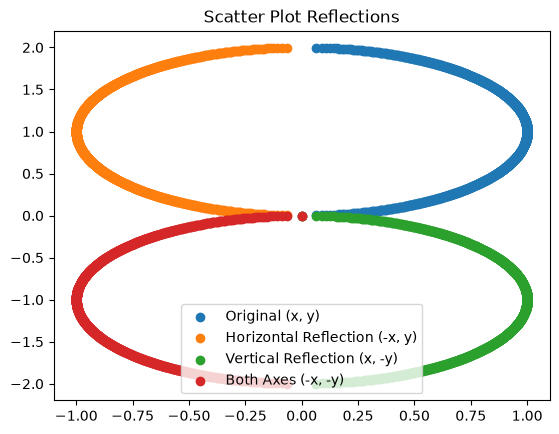

In [75]:
# STARTER CODE; DO NOT CHANGE

y_data = [i / 500 for i in range(1000)]
x_data = [math.sqrt(1 - (y - 1)**2) for y in y_data]


#Your Solution
# Plot the original values
plt.scatter(x_data, y_data, label="Original (x, y)")

# Plot the horizontal reflection
plt.scatter([-x for x in x_data], y_data, label="Horizontal Reflection (-x, y)")

# Plot the vertical reflection
plt.scatter(x_data, [-y for y in y_data], label="Vertical Reflection (x, -y)")

# Plot the reflection across both axes
plt.scatter([-x for x in x_data], [-y for y in y_data],
            label="Both Axes (-x, -y)")

# Add chart title and legend
plt.title("Scatter Plot Reflections")
plt.legend()

# Display the chart
plt.show()





**Problem 8**

**Concepts:** *matplotlib, scatter plot*

**Task:**

Create a scatter plot that produces a **spiral or tornado-like pattern**.

Steps:
1. Generate a list of radius values that gradually increase so the points move farther away from the center over time.
2. Use a sequence of angle values so that each point rotates a little more than the previous one.
3. Compute the x-coordinates by multiplying each radius value by the cosine of its angle.
4. Compute the y-coordinates by multiplying each radius value by the sine of its angle.
5. Use plt.scatter() to plot the (x, y) points.
6. Add a title to the chart.



In [76]:
#Your Solution
def create_spiral():
    """
    Create a spiral or tornado-like scatter plot.
    """
    # Generate radius values that gradually increase
    radius = np.linspace(0, 10, 500)

    # Generate angle values that rotate around the center
    angle = np.linspace(0, 10 * np.pi, 500)

    # Calculate x-coordinates using cosine
    x = radius * np.cos(angle)

    # Calculate y-coordinates using sine
    y = radius * np.sin(angle)

    # Create the scatter plot
    plt.scatter(x, y)

    # Add a title
    plt.title("Spiral Pattern")

    # Display the plot
    plt.show()



**Problem 9**

**Concepts:** *reading CSV file, scatter plot*

**Task:**

Using the helper function `read_csv_to_dict`, read a dataset stored in `p9_data.csv` containing two numerical variables.

The dataset contains the following columns:

* `dataset` (string label)

* `x` (numerical variable)

* `y` (numerical variable)

Create a scatter plot using the **x** and **y** values for the dataset.

Your plot should include:
* x-axis label
* y-axis label
* title

The goal is to visualize how the two variables relate to each other.

In [77]:
#Your Solution
def create_scatter_plot(filename):
    """
    Read a CSV file and create a scatter plot using x and y columns.
    """

    # Read the CSV file.
    data = read_csv_to_dict(filename)

    # Get the x and y values.
    x_values = np.array(data["x"], dtype=float)
    y_values = np.array(data["y"], dtype=float)

    # Create the scatter plot.
    plt.scatter(x_values, y_values)

    # Add labels and title.
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title("Relationship Between X and Y")

    # Display the plot.
    plt.show()

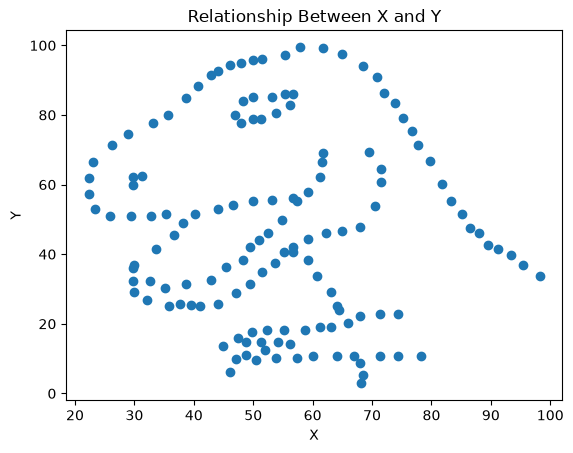

In [78]:
create_scatter_plot("p9_data.csv")

**Problem 10**

**Concepts:** *reading CSV file, line graph*

**Task:**

Write a function:

`create_line_graph(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Verify the specified column exists.
3. Convert the column values to floats.
4. Plot the values as a **line graph**.

Your graph should include:
* a title
* x-axis labeled **Day Number**
* y-axis labeled with the column name

In [79]:
#Your Solution
# Your Solution
def create_line_graph(filename, column_name):
    """Create a line graph showing stock prices over time."""

    # Read the CSV data into a dictionary.
    data = read_csv_to_dict(filename)

    # Check whether the selected column exists.
    if column_name not in data:
        raise KeyError("Column not found in CSV file.")

    # Get the selected column values.
    values = np.array(data[column_name], dtype=float)

    # Generate day numbers for the x-axis.
    days = np.arange(1, len(values) + 1)

    # Create the line graph.
    plt.figure(figsize=(12, 5))
    plt.plot(days, values)

    # Add the graph title and axis labels.
    plt.title("Starbucks Stock Price Over Time")
    plt.xlabel("Day Number")
    plt.ylabel(column_name)

    # Display the graph.
    plt.show()



In [80]:
data = read_csv_to_dict("SBUX.csv")
print(data.keys())

dict_keys(['formatted_date', 'date', 'high', 'low', 'open', 'close', 'volume', 'adjclose'])


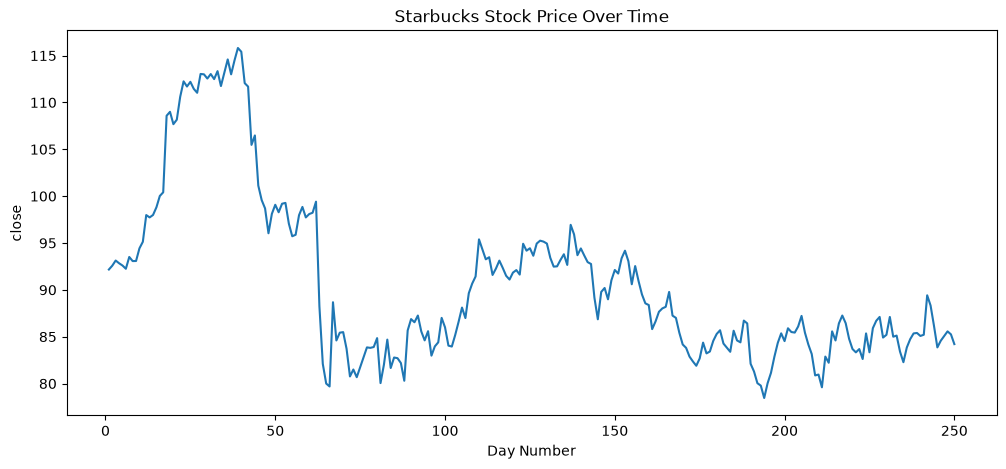

In [81]:
create_line_graph ("SBUX.csv", "close")

**Problem 11**

**Concepts:** *reading CSV file, histogram*

**Task:**

Write a function:

`create_histogram(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Convert the selected column to numeric values.
3. Create a histogram of the data.

Requirements:
* Use **at least 10 bins**.
* Add a title showing the column name.

The histogram should display the distribution of values in the selected column.

In [82]:
#Your Solution
def create_histogram(filename, column_name):
    """Create a histogram showing the distribution of stock values."""

    # Read the CSV data.
    data = read_csv_to_dict(filename)

    # Convert the selected column into a NumPy array.
    values = np.array(data[column_name], dtype=float)

    # Create the histogram.
    plt.figure(figsize=(10, 5))
    plt.hist(values, bins=15)

    # Add the graph title and labels.
    plt.title("Distribution of Starbucks Stock Prices")
    plt.xlabel(column_name)
    plt.ylabel("Frequency")

    # Display the histogram.
    plt.show()

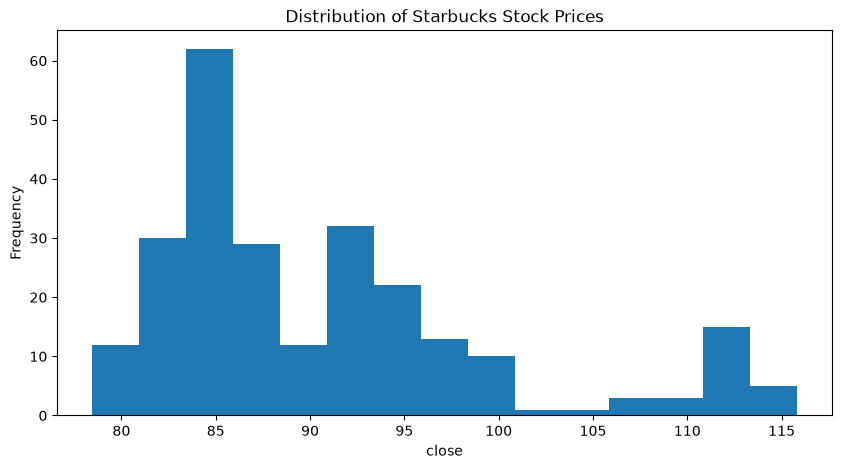

In [83]:
create_histogram("SBUX.csv", "close")

**Problem 12**

**Concepts:** *reading CSV file, pie chart*

**Task:**

Write a function:

`create_pie_chart(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Convert the selected column to numeric values.
3. Compute the **mean value** of the column.
4. Determine:
* the percentage of values **greater than the mean**
* the percentage **less than or equal to the mean**

Create a pie chart displaying these two proportions.

Include:
* labels
* percentages
* chart title

In [84]:
#Your Solution
def create_pie_chart(filename, column_name):
    """Create a pie chart showing values above and below the mean."""

    # Read the CSV data.
    data = read_csv_to_dict(filename)

    # Get the selected column values.
    values = np.array(data[column_name], dtype=float)

    # Calculate the mean.
    mean_value = np.mean(values)

    # Count values greater than the mean.
    greater_than_mean = np.sum(values > mean_value)

    # Count values less than or equal to the mean.
    less_or_equal_mean = np.sum(values <= mean_value)

    # Create the two groups.
    totals = [greater_than_mean, less_or_equal_mean]

    # Create labels for the pie chart.
    labels = ["Greater than Mean", "Less than or Equal to Mean"]

    # Create and display the pie chart.
    plt.figure(figsize=(8, 8))
    plt.pie(totals, labels=labels, autopct="%1.1f%%")
    plt.title("Values Compared to the Mean: " + column_name)
    plt.show()

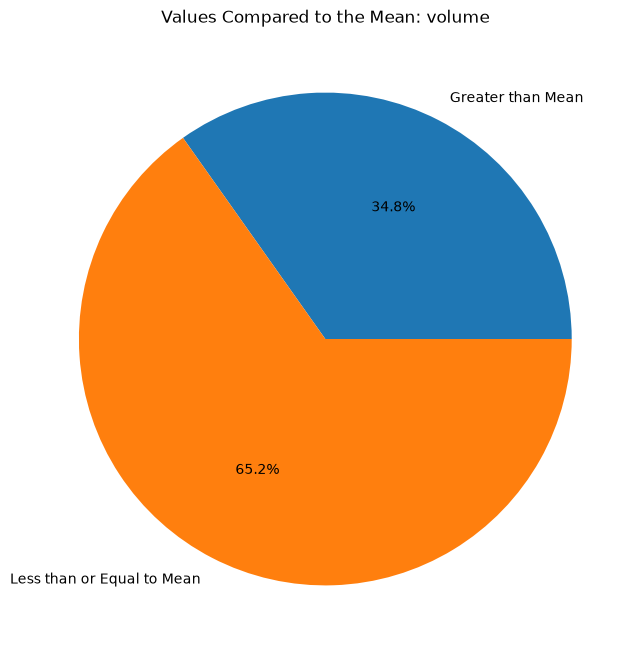

In [85]:
create_pie_chart("SBUX.csv", "volume")

**Problem 13**

**Concepts:** *reading CSV file, scatter plot*

**Task:**

Write a function:

`create_scatter_plot(filename, x_column, y_column)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Extract the specified columns.
3. Convert the values to floats.
4. Create a scatter plot showing the relationship between the two variables.

Include:
* x-axis label
* y-axis label
* title

In [86]:
#Your Solution
def create_scatter_plot(filename, x_column, y_column):
    """Create a scatter plot comparing two columns."""

    # Read the CSV data.
    data = read_csv_to_dict(filename)

    # Convert both selected columns into NumPy arrays.
    x_values = np.array(data[x_column], dtype=float)
    y_values = np.array(data[y_column], dtype=float)

    # Create the scatter plot.
    plt.figure(figsize=(10, 5))
    plt.scatter(x_values, y_values)

    # Add the graph title and axis labels.
    plt.title("Starbucks Stock Price vs. Trading Volume")
    plt.xlabel(x_column)
    plt.ylabel(y_column)

    # Display the scatter plot.
    plt.show()

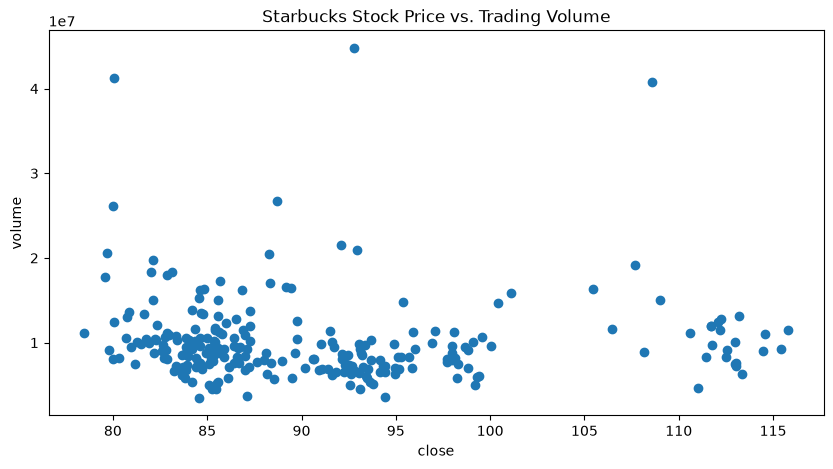

In [87]:
create_scatter_plot("SBUX.csv", "close", "volume")